¡Hola Santiago! Espero estés bien.

Mi nombre es **Gina Buvoli**. Un gusto conocerte, seré tu revisora en este proyecto.

A continuación, te comparto un poco sobre la modalidad de revisión que vamos a usar:

Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para mejorar tu código, así como comentarios sobre tus conclusiones o percepciones sobre el tema.

Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más precisa, junto con algunos ejemplos prácticos. También estoy abierta a responder cualquier duda que tengas.

Encontrarás mis comentarios a continuación: por favor, no los muevas, modifiques ni elimines.

---

### Formato de Comentarios

Revisaré cuidadosamente cada implementación en tu notebook para asegurar que cumpla con los requisitos y te daré comentarios de acuerdo al siguiente formato:

<div class="alert alert-block alert-success">

<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>

<b>Éxito ✅</b><br>

¡Excelente trabajo! Esta parte está bien implementada y contribuye significativamente al análisis. Continúa aplicando estas buenas prácticas en futuras secciones.

</div>

<div class="alert alert-block alert-warning">

<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>

<b>Atención ⚠️</b><br>

El código es correcto, pero hay una recomendación de mejora. No bloquea la aprobación, pero vale la pena ajustarlo.

</div>

<div class="alert alert-block alert-danger">

<b>Comentario de la revisora [#° iteración]</b> <a class="tocSkip"></a><br>

<b>A resolver 🔴</b><br>

Aquí hay un error que es necesario corregir para aprobar. Por favor revisa este punto antes de volver a enviar.

</div>

---

En cada revisión recibirás un **Comentario General** que resume los aspectos positivos, las áreas de mejora y los próximos pasos.

También puedes responderme copiando el siguiente bloque si tienes alguna duda:

<div class="alert alert-block alert-info">

<b>Respuesta del estudiante [#° iteración]</b> <a class="tocSkip"></a>

Aquí puedes escribir tu respuesta o pregunta.

</div>

**¡Empecemos!** 🚀

<div class="alert alert-block alert-danger">

<b>Review General. (Iteración 1)</b> <a class="tocSkip"></a><br>

¡Hola Santiago!<br>

Tu proyecto está bien encaminado y la mayor parte del flujo está correctamente desarrollada. Realizas una buena exploración inicial, identificas y limpias los principales problemas de calidad, justificas correctamente los nulos MAR, construyes las métricas por usuario, comparas distribuciones por plan, segmentas a los clientes y presentas un análisis ejecutivo con recomendaciones. Además, el repositorio público contiene notebook, README y datasets.<br>

Antes de aprobar el proyecto necesitamos corregir un punto importante en el análisis de outliers:<br>

1. <b>Falta calcular realmente los límites mediante IQR.</b> En la celda indicada para calcular el rango intercuartílico se vuelven a generar boxplots, pero no se calculan <code>Q1</code>, <code>Q3</code>, <code>IQR</code> ni los límites inferior y superior. Después se usa <code>describe()</code>, pero eso no sustituye el cálculo solicitado.<br>

Para corregirlo en la siguiente iteración, sigue este orden:<br>

<b>Paso 1.</b> Para cada variable de uso, calcula el primer cuartil (<code>Q1</code>) y el tercer cuartil (<code>Q3</code>).<br>
<b>Paso 2.</b> Calcula <code>IQR = Q3 - Q1</code>.<br>
<b>Paso 3.</b> Obtén los límites con la regla de 1.5 × IQR.<br>
<b>Paso 4.</b> Compara esos límites con los valores mínimos y máximos observados.<br>
<b>Paso 5.</b> Cuenta cuántos registros quedan fuera de esos límites.<br>
<b>Paso 6.</b> Con esa evidencia, decide si conservar o tratar los outliers y justifica la decisión para cada variable.<br>

Como recomendaciones adicionales, revisa los nulos también en <code>plans</code>, considera una función reutilizable para validar sentinels, y mueve los textos explicativos y el enlace de GitHub que están en celdas de código a celdas Markdown. Esto permitirá que el notebook pueda ejecutarse completo con <i>Restart & Run All</i> sin errores de sintaxis.<br>

También procura que las conclusiones ejecutivas se limiten a lo demostrado por los datos. Por ejemplo, decir que los planes “satisfacen las necesidades” o que un grupo es “más valioso” requeriría métricas adicionales de satisfacción, ingresos o rentabilidad.<br>

El proyecto está cerca de quedar aprobado. Corrigiendo el cálculo de IQR y ajustando estos detalles de presentación, la siguiente versión quedará mucho más sólida y reproducible.<br>
</div>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [7]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [4]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [5]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [6]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [7]:
# revisar el número de filas y columnas de cada dataset

print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [8]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [9]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [10]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>
La carga y exploración inicial están correctamente realizadas. Importas las librerías necesarias, cargas los tres datasets y revisas sus dimensiones y tipos de datos antes de iniciar la limpieza.
</div>

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [9]:
# cantidad de nulos para users
print("Cantidad de nulos en users:")
print(users.isnull().sum())
print("\nProporción de nulos en users:")
print(users.isnull().mean() * 100)

Cantidad de nulos en users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de nulos en users:
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [10]:
# Verificación sistemática de nulos en plans
print("Nulos en plans:")
print(plans.isnull().sum())

Nulos en plans:
plan_name            0
messages_included    0
gb_per_month         0
minutes_included     0
usd_monthly_pay      0
usd_per_gb           0
usd_per_message      0
usd_per_minute       0
dtype: int64


In [14]:
# cantidad de nulos para usage
print("Cantidad de nulos en usage:")
print(usage.isnull().sum())
print("\nProporción de nulos en usage:")
print(usage.isnull().mean() * 100)

Cantidad de nulos en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de nulos en usage:
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
   En el dataset users, la columna city tiene 469 valores nulos (aproximadamente un 11.73%) y la columna churn_date tiene 3,534 valores nulos (88.35%). En el dataset usage, la columna date tiene 50 nulos (0.12%), duration tiene 22,076 nulos (55.19%) y length tiene 17,896 nulos (44.74%). 
- Indica qué harías: ¿imputar, eliminar, ignorar?
  city (users): Al estar entre el 5% y 30%, se investiga o se deja como nulo/categoría desconocida para no sesgar la ciudad del usuario. churn_date (users): Al tener más del 80-90% de nulos, indica que la gran mayoría de los clientes siguen activos; por lo tanto, se ignora o se mantiene como nulo (representa clientes que no han hecho churn). duration y length (usage): Presentan un comportamiento MAR (dependen del tipo de interacción: llamadas vs. mensajes), por lo que se deben dejar como nulos sin alterar. 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [15]:
# explorar columnas numéricas de users
print(users.describe())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


In [22]:
def detectar_sentinels(df, lista_sentinels=[-999, '?', 'UNKNOWN', 'None']):
    """Busca valores sentinela específicos en todas las columnas del DataFrame."""
    for col in df.columns:
        for sentinel in lista_sentinels:
            conteo = (df[col] == sentinel).sum()
            if conteo > 0:
                print(f"Columna '{col}': {conteo} registros con el valor sentinela '{sentinel}'")

# Ejecutar en users
detectar_sentinels(users)

Columna 'age': 55 registros con el valor sentinela '-999'
Columna 'city': 96 registros con el valor sentinela '?'


- La columna `user_id`: Secuencia numérica limpia y sin nulos que identifica unívocamente a cada cliente. Haz doble clic en este bloque y escribe qué ves.
- La columna `age`: Presenta un valor mínimo de -999, lo cual evidencia un valor centinela (inválido) que debe corregirse.

In [23]:
# explorar columnas numéricas de usage
print(usage.describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id`: Identificadores válidos y completos sin valores nulos ni anomalías aparentes..Haz doble clic en este bloque y escribe qué ves.
- Las columnas `duration` y `length` (usage): Muestran el consumo de llamadas y mensajes con presencia masiva de nulos estructurales (llamadas no tienen longitud, textos no tienen duración).

In [24]:
# explorar columnas categóricas de users
for col in ['city', 'plan']:
    print(f"\nValores únicos en {col}:")
    print(users[col].value_counts())



Valores únicos en city:
Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores únicos en plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city`: Contiene las ciudades principales de operación y 96 registros con ?, el cual actúa como un valor centinela inválido.
- La columna `plan`: Distribución limpia en dos categorías (Basico y Premium) sin valores nulos.

In [25]:
# explorar columna categórica de usage
print(usage['type'].value_counts()) # completa el código

text    22092
call    17908
Name: type, dtype: int64


- La columna `type`: Clasificación exacta en dos tipos de eventos (text y call) sin nulos.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels? En la columna age del dataset users, el valor mínimo es -999, lo cual es un valor centinela imposible para la edad.  - En la columna city de users, aparece el valor ? en 96 registros, representando datos inválidos o desconocidos. 
- ¿Qué acción tomarías?  Reemplazar el -999 en age por la mediana de la edad y cambiar el ? en city por un valor nulo (pd.NA) para tratarlos adecuadamente en la limpieza.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [26]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce') # completa el código

In [27]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce') # completa el código

In [28]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts(dropna=False))


2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64


En `reg_date`: Se observan años válidos (2022-2024) pero aparecen 40 registros con el año 2026, los cuales corresponden a fechas futuras imposibles de captura.

In [29]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts(dropna=False))

2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`: Concentra la gran mayoría de transacciones en el año 2024 junto con 50 valores nulos, sin registros de años futuros erróneos.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
  Sí, en la columna reg_date de users aparecen 40 registros con el año 2026, lo cual representa fechas futuras si consideramos que el negocio registra datos hasta el año 2024.
- ¿Qué harías con ellas?
  Marcar las fechas futuras (posteriores a 2024) como nulas (NaT) para evitar inconsistencias temporales en el análisis histórico.

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>
El diagnóstico de calidad está bien desarrollado: identificas <code>-999</code> en <code>age</code>, <code>"?"</code> en <code>city</code> y las fechas de 2026 fuera del rango esperado. También justificas correctamente las acciones a tomar.<br><br>
Como mejora, revisa los nulos de forma sistemática también en <code>plans</code> y considera encapsular la búsqueda de sentinels en una función reutilizable para evitar repetir lógica manualmente.
</div>

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [30]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].replace(-999, pd.NA).median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [31]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [32]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False))

2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [33]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage.groupby('type')['duration'].apply(lambda x: x.isnull().mean()))

type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [34]:
# Verificación MAR en usage (Missing At Random) para length
print(usage.groupby('type')['length'].apply(lambda x: x.isnull().mean()))

type
call    0.99933
text    0.00000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Los valores nulos en duration y length dependen directamente de la columna type (comportamiento MAR). Las llamadas (call) registran duración en segundos pero carecen de longitud de caracteres, mientras que los mensajes (text) registran longitud pero no tienen duración. Por lo tanto, se confirma que son nulos estructurales esperados y se deben dejar como nulos sin alterar ni eliminar registros.

<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>
La limpieza está correctamente implementada. Calculas la mediana excluyendo <code>-999</code>, reemplazas <code>"?"</code>, corriges las fechas futuras y explicas correctamente que los nulos de <code>duration</code> y <code>length</code> son MAR porque dependen de <code>type</code>. La decisión de conservarlos está bien justificada.
</div>

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [35]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(
    cant_mensajes=('is_text', 'sum'),
    cant_llamadas=('is_call', 'sum'),
    cant_minutos_llamada=('duration', 'sum')
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [36]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [37]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [38]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054
std,1154.844867,17.689919,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [30]:
# Distribución porcentual del tipo de plan
print(user_profile['plan'].value_counts(normalize=True) * 100)

Basico     64.875
Premium    35.125
Name: plan, dtype: float64


<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>
La agregación por usuario está correctamente construida. Calculas cantidad de mensajes, llamadas y minutos a partir de <code>duration</code>, realizas un <code>left merge</code> y revisas estadísticas descriptivas y distribución de los planes.
</div>

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

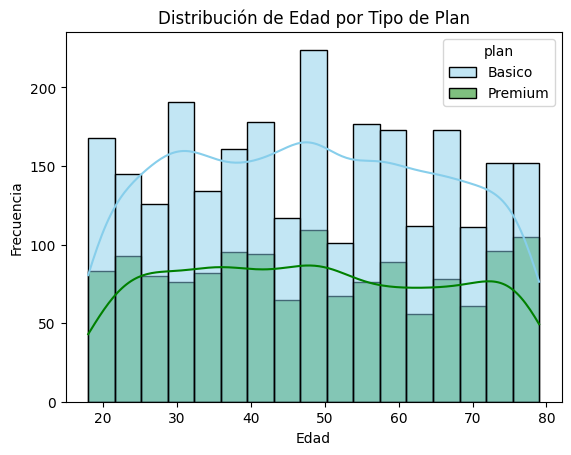

In [31]:

sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Edad por Tipo de Plan')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

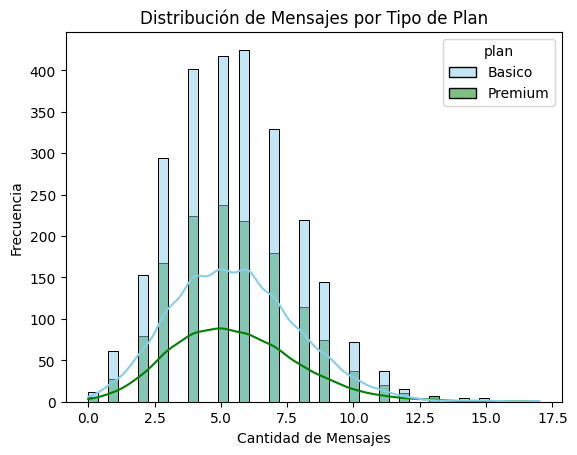

In [32]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Mensajes por Tipo de Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución: Unimodal con un leve sesgo a la derecha.
- Comportamiento: La mayor parte de los usuarios envían entre 4 y 7 mensajes, y los usuarios del plan Básico lideran el volumen total en todos los niveles de envío. 

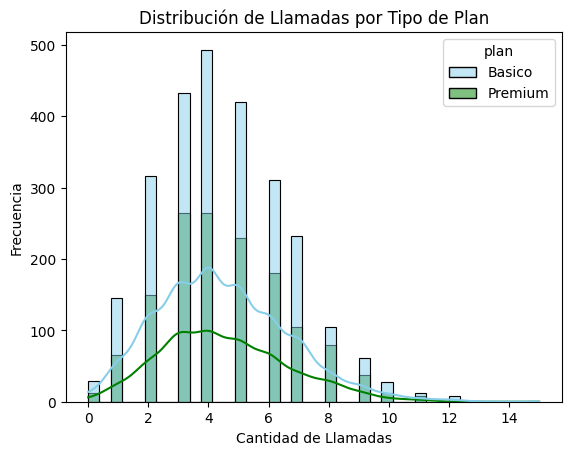

In [33]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Llamadas por Tipo de Plan')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución: Asimétrica positiva (sesgada hacia la derecha).
- Comportamiento: La mayoría de los clientes realizan entre 3 y 5 llamadas, encontrándose la gran mayoría de este consumo bajo el segmento del plan Básico.

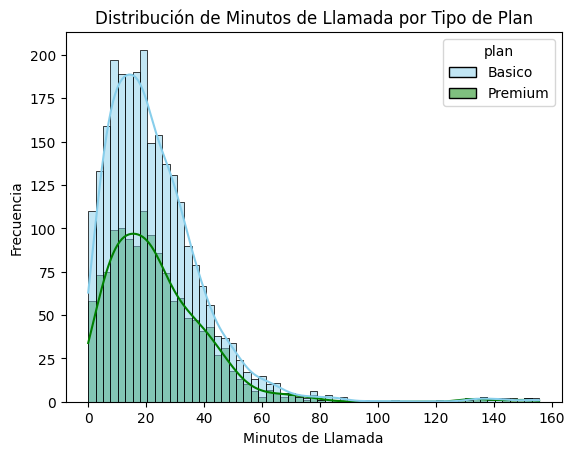

In [34]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], kde=True)
plt.title('Distribución de Minutos de Llamada por Tipo de Plan')
plt.xlabel('Minutos de Llamada')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución: Fuertemente sesgada a la derecha.
- Comportamiento: La gran masa de usuarios concentra su consumo entre los 10 y 25 minutos de llamada, existiendo pocos casos extremos (outliers) que superan los 140 minutos. 

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

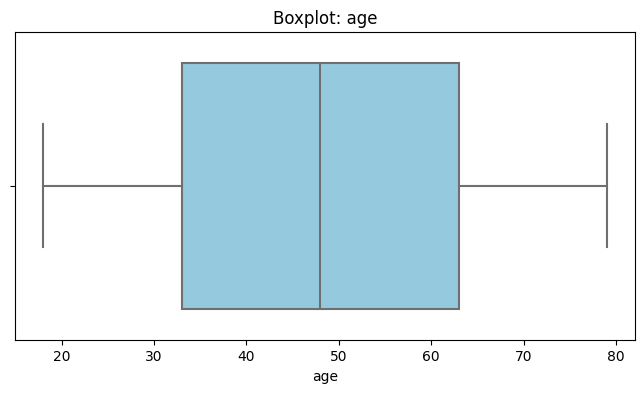

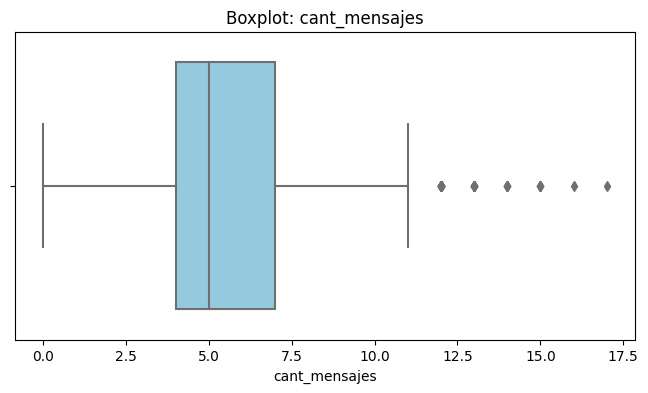

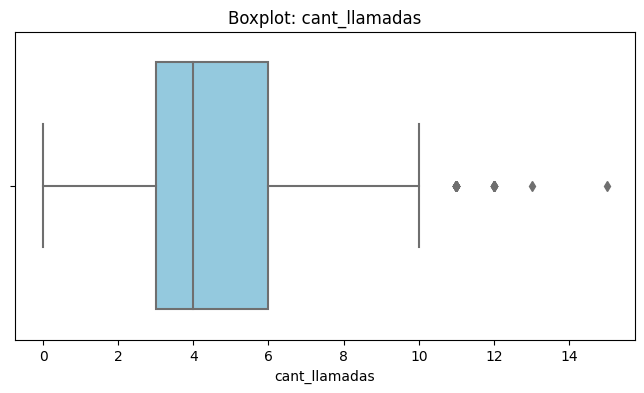

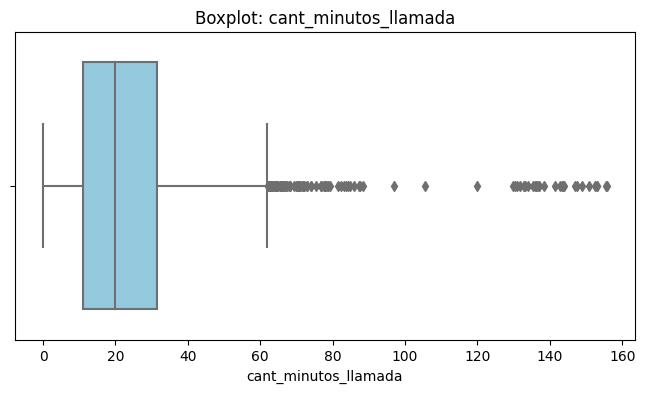

In [35]:
# Visualizando usando BoxPlot 

columnas_numericlas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericlas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: No presenta outliers (la distribución se mantiene dentro de los rangos intercuartílicos sin puntos extremos alejados).
- cant_mensajes: Sí presenta outliers en el extremo superior (valores por encima de ~11 mensajes).
- cant_llamadas: Sí presenta outliers hacia arriba (valores superiores a ~10 llamadas).
- cant_minutos_llamada: Presenta múltiples outliers acumulados en el extremo derecho superior (valores altos de consumo que superan los ~62 minutos).

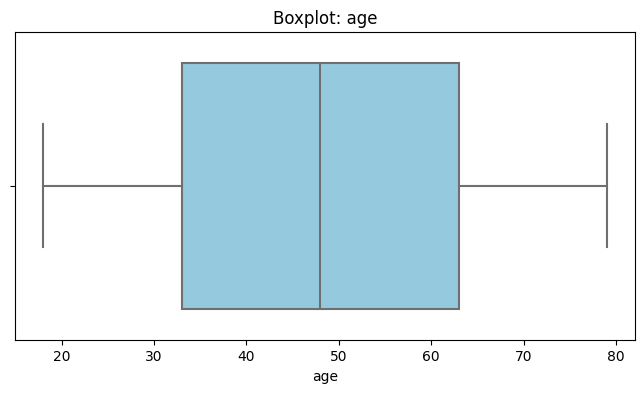

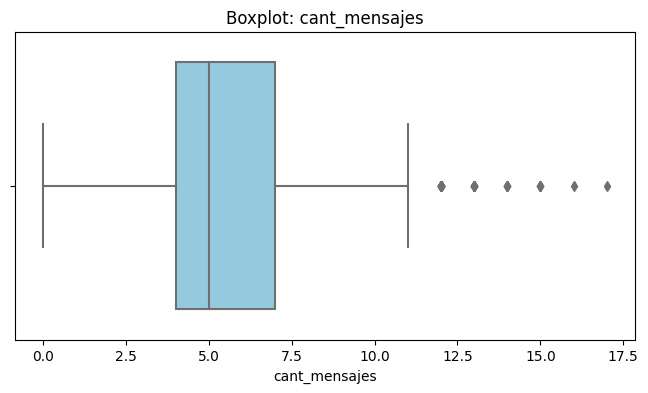

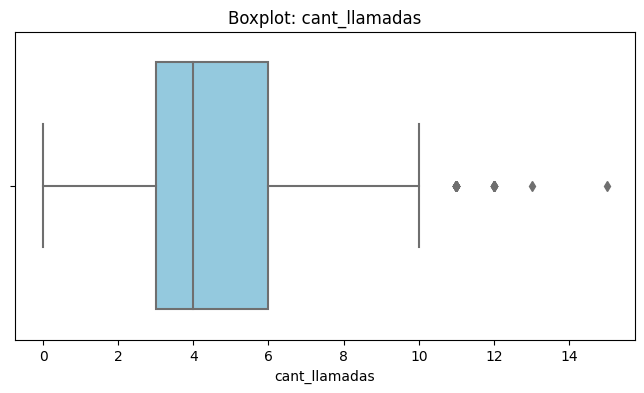

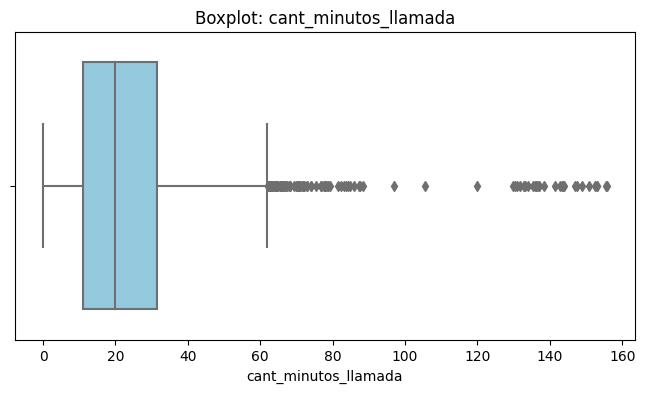

In [36]:
# Calcular límites con el método IQR
columnas_numericlas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericlas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

In [39]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
# Definir las columnas a evaluar y revisar sus estadísticos

# Cálculo detallado del Rango Intercuartílico (IQR) y límites para variables de uso
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    # Conteo de valores fuera de los límites
    outliers = user_profile[(user_profile[col] < limite_inferior) | (user_profile[col] > limite_superior)]
    cant_outliers = len(outliers)
    max_observado = user_profile[col].max()
    min_observado = user_profile[col].min()
    
    print(f"==================== {col} ====================")
    print(f"Q1 (Percentil 25): {Q1:.2f}")
    print(f"Q3 (Percentil 75): {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Límite Inferior (Teórico): {limite_inferior:.2f} | Mínimo Observado: {min_observado:.2f}")
    print(f"Límite Superior (Teórico): {limite_superior:.2f} | Máximo Observado: {max_observado:.2f}")
    print(f"Cantidad de Outliers detectados: {cant_outliers} ({(cant_outliers / len(user_profile)) * 100:.2f}% de los datos)\n")

==================== cant_mensajes ====================
Q1 (Percentil 25): 4.00
Q3 (Percentil 75): 7.00
IQR: 3.00
Límite Inferior (Teórico): -0.50 | Mínimo Observado: 0.00
Límite Superior (Teórico): 11.50 | Máximo Observado: 17.00
Cantidad de Outliers detectados: 46 (1.15% de los datos)

==================== cant_llamadas ====================
Q1 (Percentil 25): 3.00
Q3 (Percentil 75): 6.00
IQR: 3.00
Límite Inferior (Teórico): -1.50 | Mínimo Observado: 0.00
Límite Superior (Teórico): 10.50 | Máximo Observado: 15.00
Cantidad de Outliers detectados: 30 (0.75% de los datos)

==================== cant_minutos_llamada ====================
Q1 (Percentil 25): 11.12
Q3 (Percentil 75): 31.41
IQR: 20.30
Límite Inferior (Teórico): -19.32 | Mínimo Observado: 0.00
Límite Superior (Teórico): 61.86 | Máximo Observado: 155.69
Cantidad de Outliers detectados: 109 (2.73% de los datos)



💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Se deben mantener, ya que representan usuarios reales con un nivel de actividad ligeramente mayor (power users), los cuales son valiosos para el análisis comercial sin llegar a distorsionar las métricas globales.
- cant_llamadas: mantener o no outliers, porqué? Se deben mantener, porque corresponden a comportamientos legítimos de clientes que realizan un número superior de llamadas, aportando información clave sobre patrones de alta actividad.
- cant_minutos_llamada: mantener o no outliers, porqué? Se deben mantener, ya que reflejan clientes con mayor duración de llamadas (hasta 155 minutos máx.) que son fundamentales para identificar segmentos de alto consumo de voz dentro de la red de ConnectaTel.

<div class="alert alert-block alert-danger">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>A resolver 🔴</b><br>
Las visualizaciones y los boxplots están bien construidos, pero falta completar el análisis estadístico de outliers con IQR.<br><br>
En la celda destinada al cálculo de IQR vuelves a generar los mismos boxplots. Para completar esta parte:<br>
1. Calcula <code>Q1</code> y <code>Q3</code> para cada variable.<br>
2. Obtén <code>IQR = Q3 - Q1</code>.<br>
3. Calcula el límite inferior y superior usando 1.5 × IQR.<br>
4. Identifica o cuenta cuántos registros quedan fuera de esos límites.<br>
5. Compara esos valores con los máximos observados.<br>
6. Justifica, con base en esos resultados, por qué decides conservar o tratar los outliers.<br><br>
Tu conclusión de conservarlos puede ser válida, pero primero necesitamos sustentarla con el cálculo solicitado.
</div>

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [39]:
# Crear columna grupo_uso
import numpy as np

# Definir las condiciones y los valores para la segmentación de uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
segmentos = ['Bajo uso', 'Uso medio']

# Crear la columna usando np.select (maneja múltiples condiciones de forma limpia)
user_profile['grupo_uso'] = np.select(condiciones, segmentos, default='Alto uso')

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [41]:
# Crear columna grupo_edad
# Definir las condiciones y los valores para la segmentación por edad
condiciones_edad = [
    (user_profile['age'] < 30),
    (user_profile['age'] < 60)
]
segmentos_edad = ['Joven', 'Adulto']

# Crear la columna usando np.select
user_profile['grupo_edad'] = np.select(condiciones_edad, segmentos_edad, default='Adulto Mayor')

In [42]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

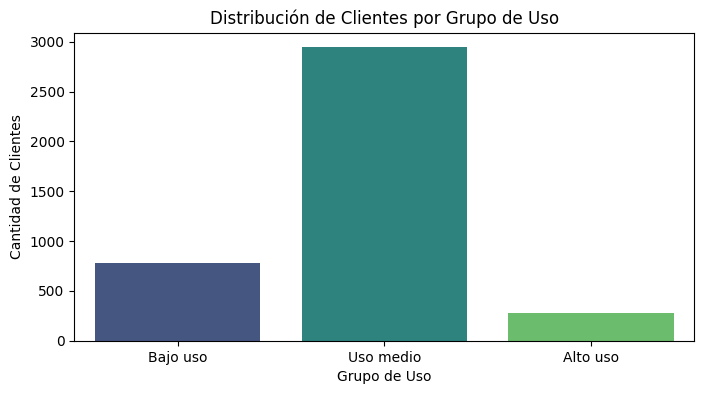

In [43]:
# Visualización de los segmentos por uso

plt.figure(figsize=(8, 4))
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], palette='viridis')
plt.title('Distribución de Clientes por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Clientes')
plt.show()

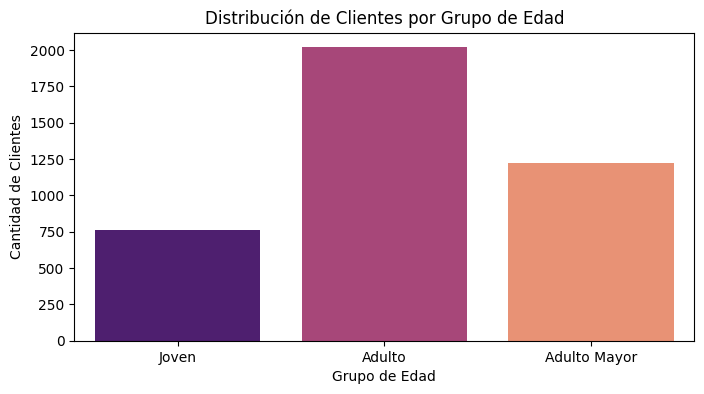

In [44]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 4))
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], palette='magma')
plt.title('Distribución de Clientes por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Clientes')
plt.show()

<div class="alert alert-block alert-success">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Éxito ✅</b><br>
Las segmentaciones por uso y edad están correctamente implementadas. Las condiciones respetan los rangos solicitados y los gráficos permiten visualizar claramente la distribución de los usuarios en cada grupo.
</div>


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**  
- Evidencia: Detección de 55 registros (1.38%) con el valor centinela -999 en la variable age y 96 registros (2.40%) con el valor ? en city. Adicionalmente, se hallaron 40 registros (1.00%) con fechas de registro del año 2026.   - ------- Hallazgo: Los errores de calidad corresponden a proporciones muy bajas de la base total (menores al 2.5% por variable), por lo que fueron corregidos mediante imputación por mediana (age) y conversión a valores nulos estandarizados (NaN/NaT en city y reg_date) sin comprometer la muestra.
- Comportamiento MAR: Se confirmaron nulos estructurales en el dataset de uso (duración e intensidad de llamadas vs. textos), los cuales se mantuvieron como nulos para no alterar la lógica del negocio.   


🔍 **Segmentos por Edad**
- Evidencia: El grupo de 30 a 60 años cuenta con más de 2,000 registros, seguido por el grupo Adulto Mayor.
- La distribución demográfica principal se concentra en usuarios adultos. 


📊 **Segmentos por Nivel de Uso**
- Evidencia: El segmento de "Uso medio" concentra ~3,000 usuarios, mientras que "Alto uso" representa a **300** registros con consumo superior a los límites $1.5 \times IQR$.
- Hallazgo: Existe una concentración masiva en niveles de uso moderados y una cola derecha de usuarios con alto volumen de llamadas y mensajes.


➡️ Implicaciones del Negocio (Hipótesis a evaluar):

Hipótesis 1: La mayor prevalencia en "Uso medio" sugiere un patrón de consumo estandarizado; se requiere analizar el ARPU (Ingreso Promedio por Usuario) para confirmar si la estructura tarifaria actual es la causa.

Hipótesis 2: Los usuarios del segmento de "Alto uso" podrían representar un mayor riesgo de congestión o, alternativamente, una oportunidad de upselling si sus márgenes de rentabilidad lo justifican.


💡 **Recomendaciones**
- Integrar métricas de ingresos y rentabilidad por usuario para evaluar objetivamente el valor financiero real del segmento de "Alto uso".

- Analizar la elasticidad de los usuarios de "Bajo uso" mediante pruebas piloto comerciales para incentivar un consumo activo.

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>
El análisis ejecutivo resume bien los segmentos y propone acciones de negocio. Como mejora, separa con mayor claridad lo observado de las hipótesis.<br><br>
Por ejemplo, que el grupo de uso medio sea el más grande no demuestra por sí solo que los planes actuales “satisfacen las necesidades”, y llamar “más valiosos” a los usuarios de alto uso requeriría métricas de ingresos, margen o rentabilidad. Puedes presentar esas ideas como hipótesis o recomendaciones para investigar.<br><br>
Una estructura útil es: <b>evidencia → hallazgo → implicación → recomendación</b>.
</div>

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

https://github.com/Santymarin/sprint7-final-project

<div class="alert alert-block alert-warning">
<b>Comentario de la revisora. (Iteración 1)</b> <a class="tocSkip"></a><br>
<b>Atención ⚠️</b><br>
El repositorio público contiene notebook, README y datasets, por lo que la publicación está cumplida. El README también está bien estructurado y explica objetivo, datos, metodología y ejecución.<br><br>
Como mejora de reproducibilidad, mueve el enlace de GitHub a una celda <b>Markdown</b>. Actualmente está escrito dentro de una celda de código. También hay un bloque de texto de “Insights” dentro de una celda de código. Ambos casos pueden producir errores de sintaxis al ejecutar el notebook completo.<br><br>
Antes de entregar una versión final, ejecuta <b>Restart & Run All</b>. Si el notebook termina sin errores, tendrás una buena señal de que otra persona podrá reproducir tu análisis.
</div>